<a href="https://colab.research.google.com/github/g25ait2138-collab/CV-Assignment/blob/main/FOVL_Word_Embeddings_G25AIT2138.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multilingual Word Embeddings for Indian Languages — FOVL Assignment

300-dimensional FastText Skip-gram embeddings trained **from scratch** on
`rony000013/indiccorpV2-5k`, evaluated against the Akhtar et&nbsp;al. (2017) word-similarity
benchmark for Gujarati, Hindi, Marathi, Punjabi, Tamil, Telugu and Urdu.

**Training restriction:** IndicCorpV2 only. No pre-trained vectors, no external corpora.
The benchmark is **evaluation data** — its human scores never enter training or model selection.

**Run order:** setup → benchmark extraction → benchmark loading → corpus → tokenization →
training → evaluation → smoke test → full run → t-SNE → analysis → experiments →
inference API → report PDF → validated ZIP.

## 0. Preparation

1. Open this notebook in Google Colab.
2. Upload `Word-Similarity-Datasets-for-Indian-Languages-master.zip` to the Colab **Files** panel.
3. Run cells in order. **Run the smoke test (section 6) before the full run (section 7).**
4. After the full run completes, download the executed notebook
   (`File → Download → Download .ipynb`) and re-upload it to `/content/FOVL_Output/`
   so the final cell can package it as reproducibility evidence.

### Changes in this corrected edition
- **Fixed cell-order defect.** The benchmark ZIP is now extracted *before* the benchmark files
  are read. In the previous version the loader ran first and failed on a clean run, which is why
  a defensive re-definition block had to exist further down.
- **Removed that defensive block** and an empty cell, along with a duplicated `load_dataset` call.
- **Added automatic PDF report generation** (section 12), so `Experimental_Report.pdf` is produced
  by the notebook instead of by hand. The final validator therefore passes end to end.
- **Added automatic notebook discovery** in the packaging cell.

## 1. Environment and configuration

In [1]:
%pip install -q "pandas==2.2.3" "pyarrow>=19,<24" datasets huggingface_hub gensim scipy scikit-learn matplotlib regex tabulate

In [2]:
from pathlib import Path
from collections import Counter
from itertools import islice
import csv, io, json, math, random, shutil, unicodedata, zipfile, hashlib, gc
import numpy as np
import pandas as pd
import regex
from scipy.stats import spearmanr, rankdata
from gensim.models import FastText
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_ID = 'rony000013/indiccorpV2-5k'
DIM = 300                 # Exactly 300: assignment requirement
LANGUAGES = ['Gujarati', 'Hindi', 'Marathi', 'Punjabi', 'Tamil', 'Telugu', 'Urdu']
LANG_CODE = {'Gujarati':'gu','Hindi':'hi','Marathi':'mr','Punjabi':'pa',
             'Tamil':'ta','Telugu':'te','Urdu':'ur'}
LANG_ALIASES = {
    'Gujarati':['gu','guj','guj_gujr','gujarati'],
    'Hindi':['hi','hin','hin_deva','hindi'],
    'Marathi':['mr','mar','mar_deva','marathi'],
    'Punjabi':['pa','pan','pan_guru','punjabi','panjabi'],
    'Tamil':['ta','tam','tam_taml','tamil'],
    'Telugu':['te','tel','tel_telu','telugu'],
    'Urdu':['ur','urd','urd_arab','urdu']}
ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'FOVL_Output'
BENCH_DIR = OUT / 'benchmark'
MODELS_DIR = OUT / 'models'
EMB_DIR = OUT / 'embeddings'
VOC_DIR = OUT / 'vocabulary'
FIG_DIR = OUT / 'figures'
TABLE_DIR = OUT / 'tables'
for folder in (OUT, BENCH_DIR, MODELS_DIR, EMB_DIR, VOC_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# A smoke test must never overwrite the final model artifacts.
SMOKE_DOCS = 100
SMOKE_EPOCHS = 2
FULL_DOCS = None   # None = all available records, without truncating the dataset
FULL_EPOCHS = 15
FT_ARGS = dict(vector_size=DIM, window=5, min_count=2, sg=1, negative=10,
               min_n=2, max_n=5, bucket=20_000, sample=1e-4,
               workers=2, seed=SEED)
print('Dataset:', DATASET_ID)
print('Languages:', ', '.join(LANGUAGES))
print('Output directory:', OUT)

Dataset: rony000013/indiccorpV2-5k
Languages: Gujarati, Hindi, Marathi, Punjabi, Tamil, Telugu, Urdu
Output directory: /content/FOVL_Output


## 2. Import the word-similarity benchmark (evaluation only)

**Order matters:** the archive is extracted first, then parsed. The repository ZIP holds exactly
seven `*-WS.txt` files.

These files contain real irregularities, which are accommodated rather than repaired:
the **Hindi file is comma-separated** while the others are predominantly tab-separated;
**Marathi has 149 rows with no human score**; **Tamil has one row with a blank word**; some files
carry a UTF-8 BOM. Every row is preserved in its original position for the `(N, 2, 300)` exports.
Rows lacking a valid score or word are excluded from the Spearman calculation only.

### 2.1 Extract the archive

In [3]:
# Find an uploaded benchmark archive or allow the user to upload one in Colab.
ZIP_NAME = 'Word-Similarity-Datasets-for-Indian-Languages-master.zip'
zip_candidates = [ROOT / ZIP_NAME, Path.cwd() / ZIP_NAME, OUT / ZIP_NAME]
BENCH_ZIP = next((p for p in zip_candidates if p.exists()), None)
if BENCH_ZIP is None:
    try:
        from google.colab import files
        print('Upload your benchmark ZIP now:')
        uploaded = files.upload()
        BENCH_ZIP = ROOT / ZIP_NAME if ZIP_NAME in uploaded else None
    except ImportError:
        pass
assert BENCH_ZIP is not None and BENCH_ZIP.is_file(), (
    'Benchmark ZIP not found. Upload Word-Similarity-Datasets-for-Indian-Languages-master.zip.'
)
with zipfile.ZipFile(BENCH_ZIP) as z:
    members = [x for x in z.namelist() if x.endswith('-WS.txt')]
    print('Benchmark files:', [Path(x).name for x in members])
    assert len(members) == 7, 'Expected seven language benchmark files.'
    for name in members:
        dest = BENCH_DIR / Path(name).name
        dest.write_bytes(z.read(name))
print('Benchmark extracted:', BENCH_DIR)

Benchmark files: ['Gujarati-WS.txt', 'Hindi-WS.txt', 'Marathi-WS.txt', 'Punjabi-WS.txt', 'Tamil-WS.txt', 'Telugu-WS.txt', 'Urdu-WS.txt']
Benchmark extracted: /content/FOVL_Output/benchmark


### 2.2 Parse the benchmark files



In [4]:
def load_benchmark(language):
    file = BENCH_DIR / f'{language}-WS.txt'
    assert file.is_file(), f'Missing benchmark file: {file.name}'
    pairs, scores = [], []
    for lineno, raw in enumerate(file.read_text(encoding='utf-8-sig').splitlines(), 1):
        # Do not drop rows. Always keep original source positions.
        sep = '\t' if '\t' in raw else ','
        fields = next(csv.reader([raw], delimiter=sep))
        if len(fields) < 2:
            raise ValueError(f'{file.name}:{lineno}: fewer than two word fields')
        w1 = unicodedata.normalize('NFC', fields[0].strip())
        w2 = unicodedata.normalize('NFC', fields[1].strip())
        raw_score = fields[2].strip() if len(fields) > 2 else ''
        try:
            score = float(raw_score) if raw_score else float('nan')
        except ValueError:
            score = float('nan')
        pairs.append((w1, w2))
        scores.append(score)
    assert pairs, f'Empty benchmark for {language}'
    return {'pairs':pairs, 'scores':np.asarray(scores, dtype=np.float64)}

BENCH = {lang:load_benchmark(lang) for lang in LANGUAGES}
benchmark_rows = []
for lang, entry in BENCH.items():
    pairs, scores = entry['pairs'], entry['scores']
    valid = sum(bool(a and b and np.isfinite(s)) for (a,b),s in zip(pairs,scores))
    benchmark_rows.append({'Language':lang, 'Total rows':len(pairs),
                           'Valid scored rows':valid, 'Excluded from rho':len(pairs)-valid})
benchmark_df = pd.DataFrame(benchmark_rows)
print(benchmark_df.to_string(index=False))
assert all(len(BENCH[l]['pairs'])>0 for l in LANGUAGES)

Language  Total rows  Valid scored rows  Excluded from rho
Gujarati         163                163                  0
   Hindi         235                235                  0
 Marathi         253                104                149
 Punjabi         143                143                  0
   Tamil          97                 96                  1
  Telugu         111                111                  0
    Urdu         100                100                  0


## 3. Load the IndicCorpV2 training corpus

The assignment specifies `load_dataset("rony000013/indiccorpV2-5k")`. Rather than assuming a
column layout, this section inspects the actual schema and resolves language codes through an
alias table. It raises rather than substituting outside text if any of the seven languages cannot
be identified.

In [6]:
from datasets import load_dataset

ds = load_dataset("rony000013/indiccorpV2-5k")

In [7]:
from datasets import load_dataset, get_dataset_config_names

# Required by the assignment specification:
ds = load_dataset("rony000013/indiccorpV2-5k")

raw_dataset = ds
print(raw_dataset)
try:
    print('Available configs:', get_dataset_config_names(DATASET_ID))
except Exception as exc:
    print('Config listing unavailable:', type(exc).__name__)

# Inspect every split before extraction.
if hasattr(raw_dataset, 'keys'):
    for split_name, split in raw_dataset.items():
        print('Split:', split_name, 'rows:', len(split), 'columns:', split.column_names)
        if len(split):
            print('Field types:', {k: type(v).__name__ for k, v in split[0].items()})
else:
    print('Columns:', raw_dataset.column_names)

DatasetDict({
    train: Dataset({
        features: ['language', 'code', 'text'],
        num_rows: 118243
    })
})
Available configs: ['default']
Split: train rows: 118243 columns: ['language', 'code', 'text']
Field types: {'language': 'str', 'code': 'str', 'text': 'str'}


In [8]:
def choose_column(columns, choices):
    lookup = {c.lower():c for c in columns}
    for name in choices:
        if name in lookup:
            return lookup[name]
    return None

def resolve_language(code):
    key = str(code).lower().replace('-', '_').strip()
    for language, aliases in LANG_ALIASES.items():
        if key in aliases or key.split('_')[0] in aliases:
            return language
    return None

def collect_corpora(dataset):
    text_by_lang = {l:[] for l in LANGUAGES}
    splits = dataset.items() if hasattr(dataset, 'items') else [('train', dataset)]
    for split_name, ds in splits:
        if len(ds) == 0: continue
        columns = ds.column_names
        text_col = choose_column(columns, ['text','content','sentence','document','raw','line'])
        lang_col = choose_column(columns, ['code','language','lang','lang_code','language_code'])
        assert text_col, f'No identifiable text column in split {split_name}: {columns}'
        if lang_col is None:
            fixed_language = resolve_language(split_name)
            assert fixed_language, (f'Language column missing in split {split_name}; '
                                    'manual verification required before training.')
            for record in ds:
                t = record[text_col]
                if isinstance(t, str) and t.strip(): text_by_lang[fixed_language].append(t)
        else:
            for record in ds:
                language = resolve_language(record[lang_col])
                t = record[text_col]
                if language in text_by_lang and isinstance(t, str) and t.strip():
                    text_by_lang[language].append(t)
        print('Processed split:',split_name,'text column:',text_col,'language column:',lang_col)
    missing = [l for l, docs in text_by_lang.items() if not docs]
    assert not missing, f'Missing training languages: {missing}. Stop and inspect actual codes.'
    return text_by_lang

TEXT_BY_LANG = collect_corpora(raw_dataset)
corpus_counts = pd.DataFrame([{'Language':l,'Documents':len(TEXT_BY_LANG[l])} for l in LANGUAGES])
# Avoid using display() on raw DataFrame to prevent pandas 3.1.x compatibility errors with Colab interactive outputs
print(corpus_counts.to_string(index=False))
assert len(TEXT_BY_LANG)==7

Processed split: train text column: text language column: code
Language  Documents
Gujarati       5000
   Hindi       5000
 Marathi       5000
 Punjabi       5000
   Tamil       5000
  Telugu       5000
    Urdu       5000


## 4. Unicode normalization and tokenization

Training and evaluation share one preprocessing path, which removes any normalization drift.
NFC preserves canonically equivalent Unicode forms, and the token pattern matches letters,
combining marks and digits by Unicode category — so a single code path serves all six scripts.

In [9]:
TOKEN_PATTERN = regex.compile(r"[\p{L}\p{M}\p{N}]+(?:[-'’][\p{L}\p{M}\p{N}]+)*")

def tokenize(text):
    normalized = unicodedata.normalize('NFC', str(text)).casefold()
    return TOKEN_PATTERN.findall(normalized)

def to_sentences(texts, max_docs=None):
    selected = texts if max_docs is None else texts[:max_docs]
    sentences = [tok for text in selected if (tok := tokenize(text)) and len(tok)>=2]
    if not sentences:
        raise ValueError('No usable tokenized sentences.')
    return sentences

sample = 'अच्छा छात्र विद्यालय में पढ़ता है।'
print('Raw:',sample)
print('Tokens:',tokenize(sample))

Raw: अच्छा छात्र विद्यालय में पढ़ता है।
Tokens: ['अच्छा', 'छात्र', 'विद्यालय', 'में', 'पढ़ता', 'है']


## 5. Train from scratch (FastText Skip-gram, exactly 300 dimensions)

One monolingual model per language. `FastText()` builds a **new randomly initialized model**;
nothing is loaded or fine-tuned from external vectors. Character n-grams give coverage for unseen
words, and `WordVectorResolver` adds a frequency-weighted corpus-mean fallback so that even a
blank or degenerate input returns a finite, non-zero-norm 300-D vector.

In [10]:
def train_language(language, max_docs=None, epochs=FULL_EPOCHS, persist=True, params=None):
    sentences = to_sentences(TEXT_BY_LANG[language], max_docs=max_docs)
    cfg = dict(FT_ARGS)
    if params: cfg.update(params)
    cfg['epochs'] = epochs
    assert cfg['vector_size']==300, 'Embedding dimension must be exactly 300.'
    model = FastText(**cfg)
    model.build_vocab(corpus_iterable=sentences)
    if len(model.wv)==0: raise ValueError(f'{language}: zero-size vocabulary')
    model.train(corpus_iterable=sentences, total_examples=len(sentences), epochs=epochs)
    assert model.wv.vector_size == 300
    if persist:
        model.save(str(MODELS_DIR / f'{language}_fasttext.model'))
    stats={'Language':language, 'Documents used':len(TEXT_BY_LANG[language]) if max_docs is None else min(max_docs,len(TEXT_BY_LANG[language])),
           'Training sentences':len(sentences), 'Vocabulary':len(model.wv), 'Epochs':epochs}
    return model, stats

class WordVectorResolver:
    # FastText OOV plus robust fallback for blank/degenerate inputs.
    def __init__(self, model):
        assert model.wv.vector_size==300
        self.kv=model.wv
        self._mean=None

    def fallback(self):
        if self._mean is None:
            vectors=np.asarray(self.kv.vectors,dtype=np.float64)
            counts=np.array([self.kv.get_vecattr(w,'count') for w in self.kv.index_to_key], dtype=np.float64)
            if not len(vectors): raise ValueError('Cannot compute fallback from empty model.')
            weighted=np.average(vectors,axis=0,weights=counts if counts.sum()>0 else None)
            if np.linalg.norm(weighted)<1e-10:
                weighted=vectors[np.argmax(np.linalg.norm(vectors,axis=1))]
            self._mean=np.asarray(weighted,dtype=np.float32)
        return self._mean.copy()

    def vector(self, text):
        tokens=tokenize(text)
        v=[]
        for token in tokens:
            try:
                candidate=np.asarray(self.kv[token], dtype=np.float32)  # Includes FastText OOV subwords
                if candidate.shape==(300,) and np.isfinite(candidate).all() and np.linalg.norm(candidate)>1e-10:
                    v.append(candidate)
            except (KeyError, ValueError, IndexError):
                pass
        value=np.mean(v,axis=0) if v else self.fallback()
        if not np.isfinite(value).all() or np.linalg.norm(value)<1e-10:
            value=self.fallback()
        return np.asarray(value,dtype=np.float32)

    def is_in_vocab(self,text):
        tokens=tokenize(text)
        return bool(tokens) and all(t in self.kv.key_to_index for t in tokens)

print('Training function and OOV inference are ready.')

Training function and OOV inference are ready.


## 6. Evaluation: cosine similarity, Spearman correlation, OOV coverage

Every original benchmark pair — including unscored rows and rows with a blank word — produces two
vectors, so **no pair is removed from the exported arrays**. Spearman uses only rows with a valid
human score and non-blank words.

In [11]:
def cosine_similarity(a, b):
    a=np.asarray(a,dtype=np.float64);b=np.asarray(b,dtype=np.float64)
    denominator=np.linalg.norm(a)*np.linalg.norm(b)
    return float(np.dot(a,b)/denominator) if denominator>1e-20 else 0.0

def evaluate_language(language, model):
    resolver=WordVectorResolver(model)
    pairs=BENCH[language]['pairs']; human=BENCH[language]['scores']
    arr=np.empty((len(pairs),2,DIM),dtype=np.float32)
    similarities=[]
    for i,(w1,w2) in enumerate(pairs):
        arr[i,0]=resolver.vector(w1)
        arr[i,1]=resolver.vector(w2)
        similarities.append(cosine_similarity(arr[i,0],arr[i,1]))
    similarities=np.asarray(similarities,dtype=np.float64)
    valid=np.array([bool(a and b) and np.isfinite(score) for (a,b),score in zip(pairs,human)],dtype=bool)
    if valid.sum()<3: raise ValueError(f'{language}: fewer than 3 scored valid pairs')
    rho,pval=spearmanr(human[valid],similarities[valid])
    if not np.isfinite(rho): raise ValueError(f'{language}: Spearman undefined')
    unique_words=sorted({w for pair in pairs for w in pair if w})
    in_vocab=sum(resolver.is_in_vocab(w) for w in unique_words)
    result={'Language':language,'N':len(pairs),'Scored pairs':int(valid.sum()),
            'Spearman':float(rho),'p-value':float(pval),
            'Unique words':len(unique_words),'In vocabulary':in_vocab,
            'OOV':len(unique_words)-in_vocab,
            'Coverage':in_vocab/len(unique_words) if unique_words else 0.0,
            'OOV rate':1-in_vocab/len(unique_words) if unique_words else 0.0}
    return result, arr, similarities, resolver

print('Evaluation functions are ready.')

Evaluation functions are ready.


## 7. Smoke test (100 documents, 2 epochs)

Validates imports, training, OOV inference and evaluation on a tiny slice, so configuration errors
surface in minutes rather than after a 40-minute run. **These scores are never reported as final**,
and smoke-test models are never persisted.

In [12]:
SMOKE_RESULTS = []
for language in LANGUAGES:
    model, stats = train_language(language, max_docs=SMOKE_DOCS, epochs=SMOKE_EPOCHS, persist=False)
    result, arr, sims, resolver = evaluate_language(language, model)
    assert arr.shape == (len(BENCH[language]['pairs']), 2, 300)
    assert resolver.vector('unseen_test_word_987').shape == (300,)
    SMOKE_RESULTS.append({'Language': language,
                          'Spearman (smoke only)': result['Spearman'],
                          'Vector shape': str(arr.shape)})
    del model, resolver, arr
    gc.collect()

# to_string() avoids a pandas 3.1.x display() incompatibility in Colab
print(pd.DataFrame(SMOKE_RESULTS).to_string(index=False))
print('SMOKE TEST PASSED - do not report these scores as final results.')

Language  Spearman (smoke only)  Vector shape
Gujarati              -0.082625 (163, 2, 300)
   Hindi              -0.070015 (235, 2, 300)
 Marathi              -0.062722 (253, 2, 300)
 Punjabi              -0.055180 (143, 2, 300)
   Tamil               0.081298  (97, 2, 300)
  Telugu              -0.015745 (111, 2, 300)
    Urdu              -0.141927 (100, 2, 300)
SMOKE TEST PASSED - do not report these scores as final results.


## 8. Full training, evaluation and artifact export

Trains all seven models on the full allowed subset and writes the submission artifacts:
`(N, 2, 300)` float32 arrays in original pair order, vocabulary mappings with word→position
indexes, per-pair prediction tables, and the saved models.

In [13]:
def export_language(language,model,result,array,similarities):
    N=len(BENCH[language]['pairs'])
    assert array.shape==(N,2,300) and array.dtype==np.float32
    assert np.isfinite(array).all() and (np.linalg.norm(array,axis=2)>1e-10).all()
    np.save(EMB_DIR / f'{language}.npy',array)
    pairs=BENCH[language]['pairs']
    positions={}
    for i,(a,b) in enumerate(pairs):
        positions.setdefault(a,[]).append([i,0])
        positions.setdefault(b,[]).append([i,1])
    meta={'language':language,'original_pair_count':N,'embedding_shape':[N,2,300],
          'pair_order':[[a,b] for a,b in pairs],
          'word_to_positions':positions,
          'note':'Blank words retained in original order and handled with fallback.'}
    (VOC_DIR / f'{language}_vocab.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
    rows=[]
    for i,((a,b),h,s) in enumerate(zip(pairs,BENCH[language]['scores'],similarities)):
        rows.append({'row':i,'word_1':a,'word_2':b,'human_score':h,'cosine_similarity':s,
                     'valid_for_spearman':bool(a and b and np.isfinite(h))})
    pd.DataFrame(rows).to_csv(TABLE_DIR/f'{language}_pair_predictions.csv',index=False,encoding='utf-8-sig')

FULL_RESULTS=[]
TRAINING_STATS=[]
for language in LANGUAGES:
    print('\nTRAINING:',language)
    model,stats=train_language(language,max_docs=FULL_DOCS,epochs=FULL_EPOCHS,persist=True)
    result,array,sims,resolver=evaluate_language(language,model)
    export_language(language,model,result,array,sims)
    FULL_RESULTS.append(result)
    TRAINING_STATS.append(stats)
    print('Spearman:',round(result['Spearman'],5),'Coverage:',round(result['Coverage'],4))
    del model,array,sims,resolver
    gc.collect()

assert {r['Language'] for r in FULL_RESULTS}==set(LANGUAGES)
assert all(np.isfinite(r['Spearman']) for r in FULL_RESULTS)
MACRO_AVG=float(np.mean([r['Spearman'] for r in FULL_RESULTS]))

# Avoid display() on raw DataFrame to prevent pandas 3.1.x compatibility crashes in Colab
print(pd.DataFrame(FULL_RESULTS).to_string(index=False))
print('FINAL PUBLIC MACRO-AVERAGE SPEARMAN:',round(MACRO_AVG,6))
pd.DataFrame(FULL_RESULTS).to_csv(TABLE_DIR/'language_results.csv',index=False)
pd.DataFrame(TRAINING_STATS).to_csv(TABLE_DIR/'training_statistics.csv',index=False)
(TABLE_DIR/'results.json').write_text(json.dumps({'macro_average':MACRO_AVG,'languages':FULL_RESULTS,
                              'training':TRAINING_STATS,'dataset_id':DATASET_ID,
                              'embedding_dim':DIM},indent=2),encoding='utf-8')


TRAINING: Gujarati
Spearman: 0.30444 Coverage: 0.7964

TRAINING: Hindi
Spearman: 0.19365 Coverage: 0.8082

TRAINING: Marathi
Spearman: 0.1652 Coverage: 0.7418

TRAINING: Punjabi
Spearman: 0.28133 Coverage: 0.8252

TRAINING: Tamil
Spearman: 0.19345 Coverage: 0.75

TRAINING: Telugu
Spearman: 0.22666 Coverage: 0.675

TRAINING: Urdu
Spearman: 0.23162 Coverage: 0.863
Language   N  Scored pairs  Spearman  p-value  Unique words  In vocabulary  OOV  Coverage  OOV rate
Gujarati 163           163  0.304444 0.000078           221            176   45  0.796380  0.203620
   Hindi 235           235  0.193653 0.002872           318            257   61  0.808176  0.191824
 Marathi 253           104  0.165196 0.093768           337            250   87  0.741840  0.258160
 Punjabi 143           143  0.281330 0.000665           206            170   36  0.825243  0.174757
   Tamil  97            96  0.193449 0.058965           136            102   34  0.750000  0.250000
  Telugu 111           111  0.2266

3327

## 9. t-SNE visualization — 100 words per language

Embeddings stay 300-dimensional everywhere except this figure. Points are labelled with numeric
IDs because Colab lacks fonts for all six scripts; each figure ships with a CSV mapping IDs back
to words and coordinates.

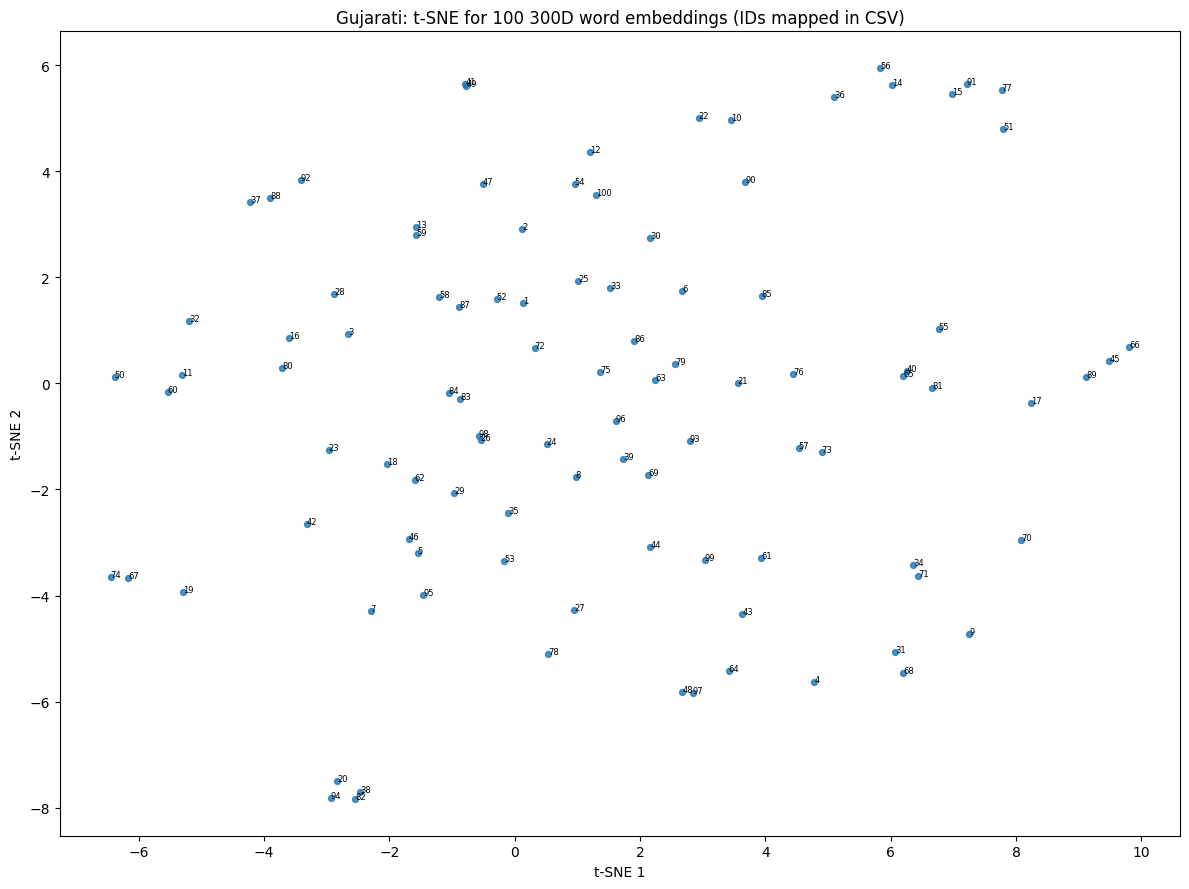

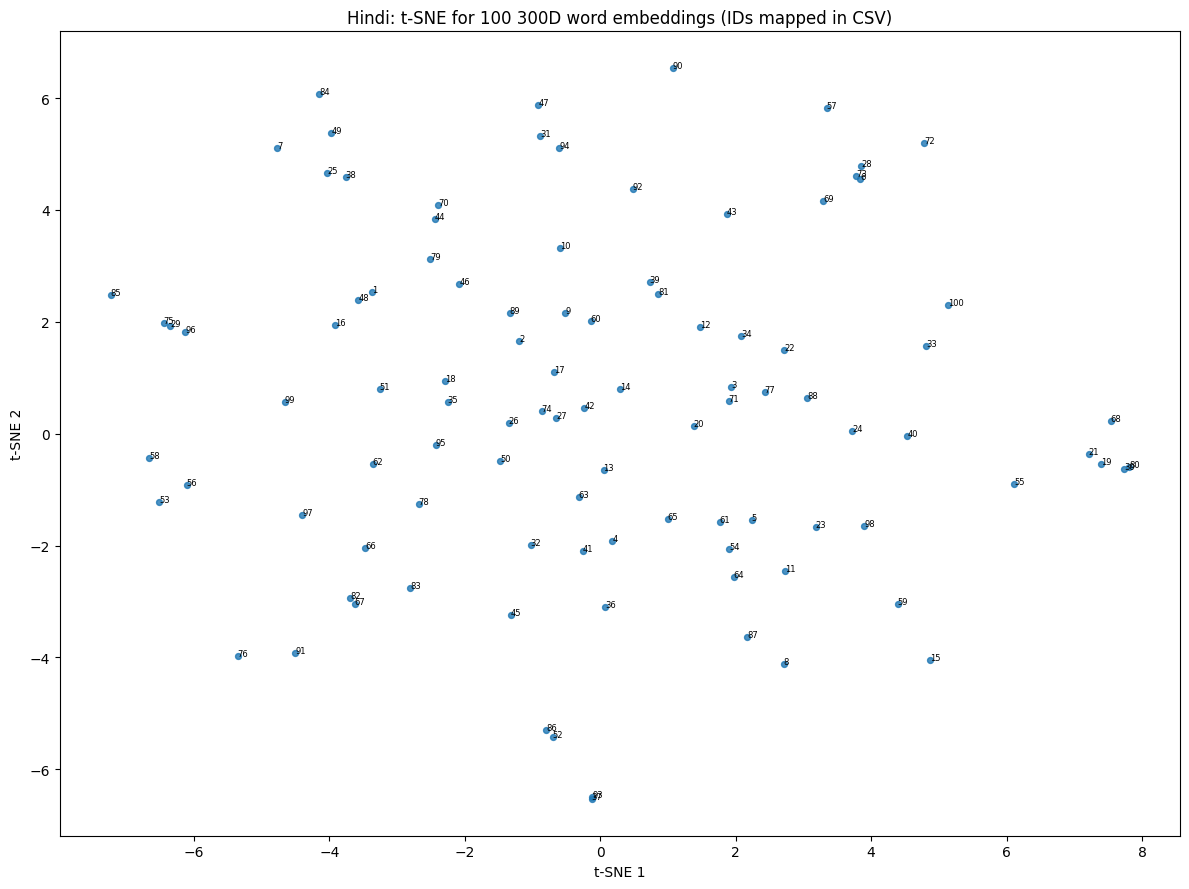

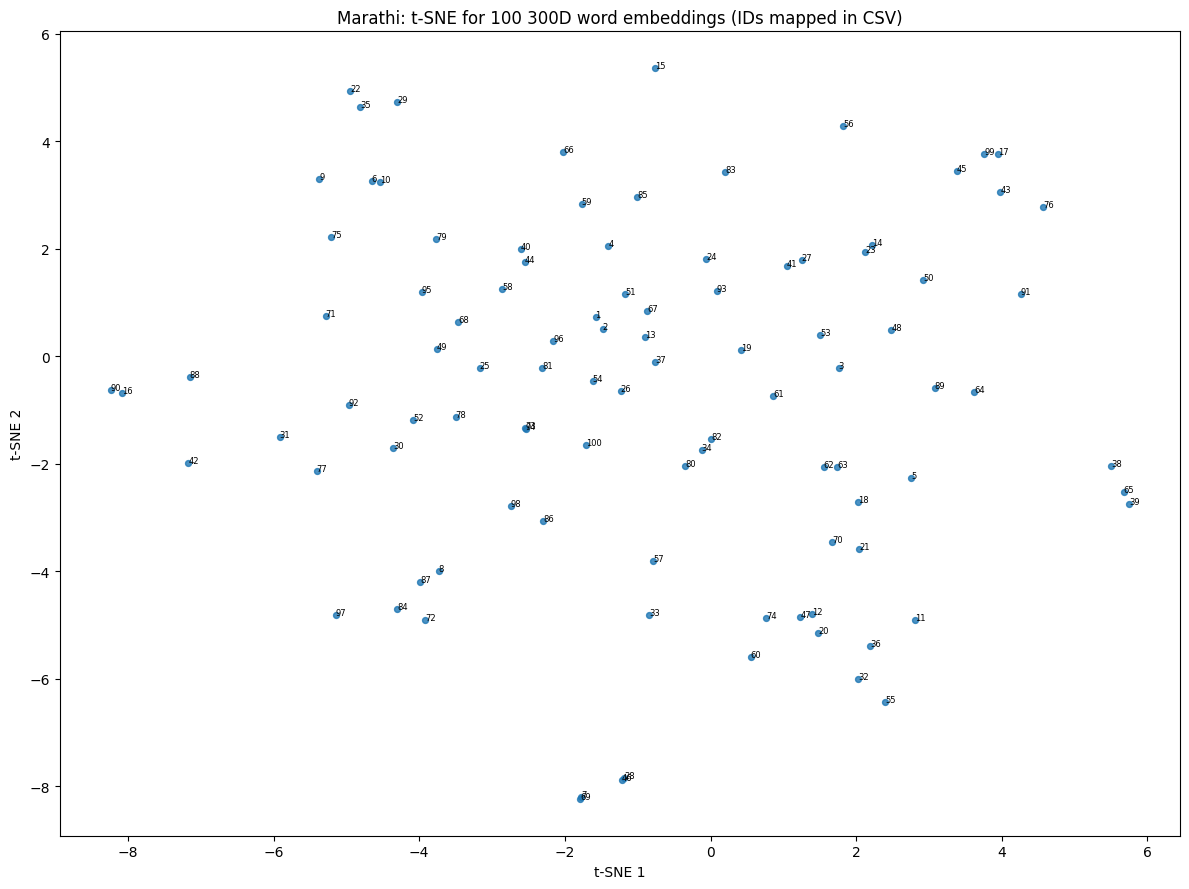

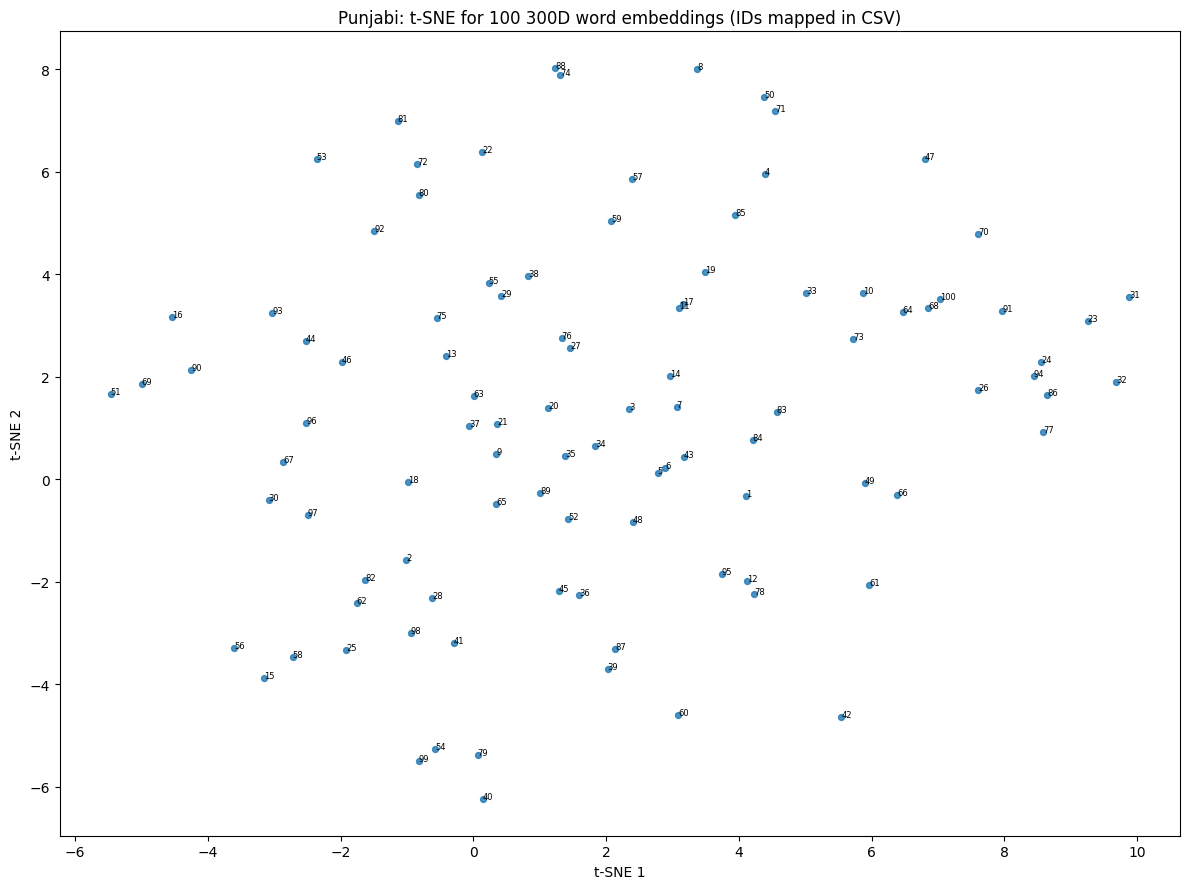

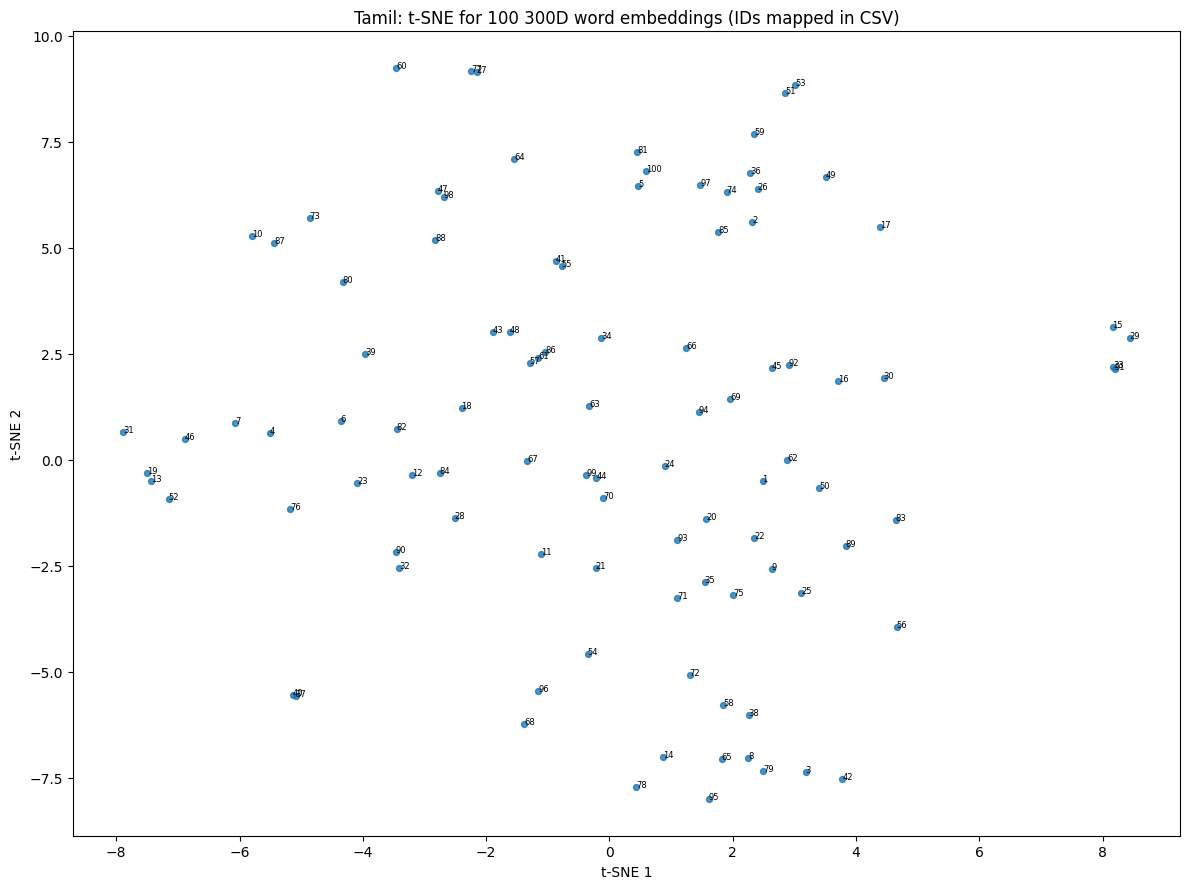

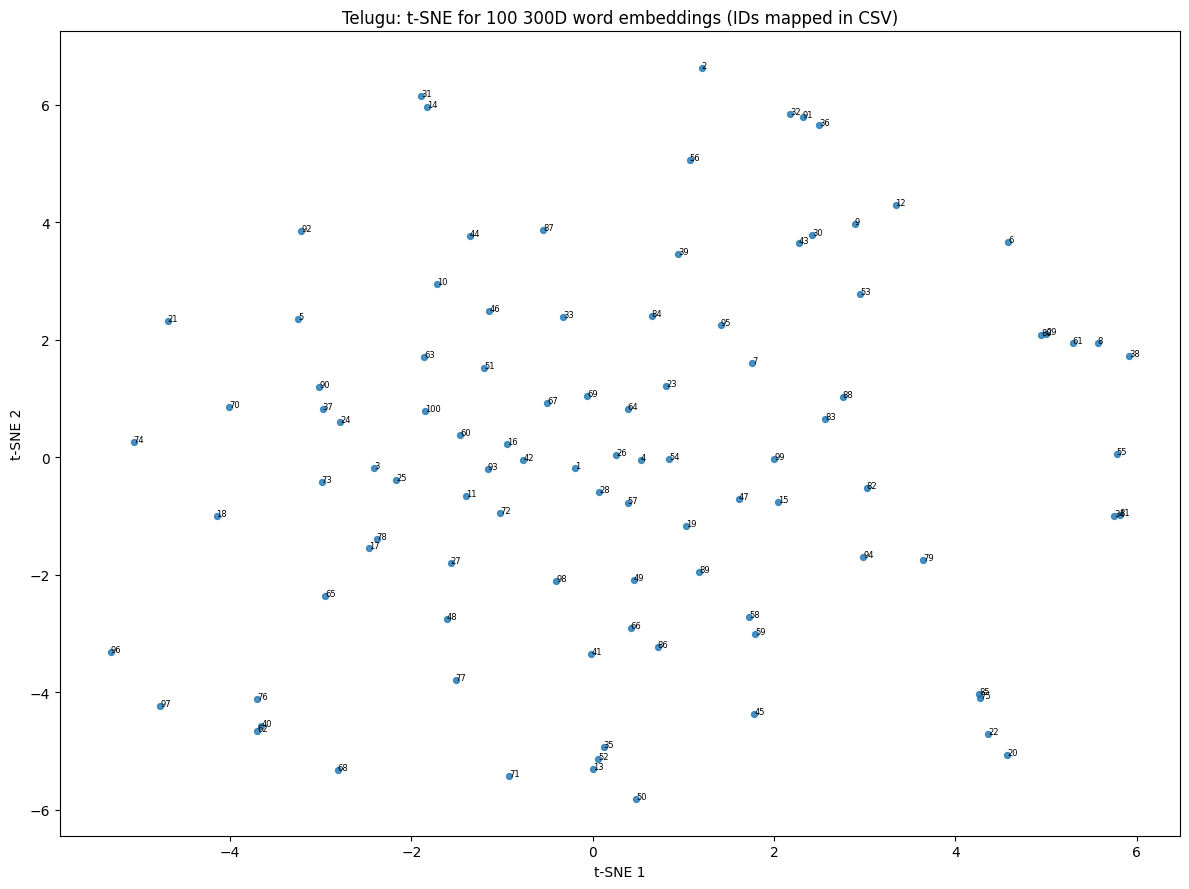

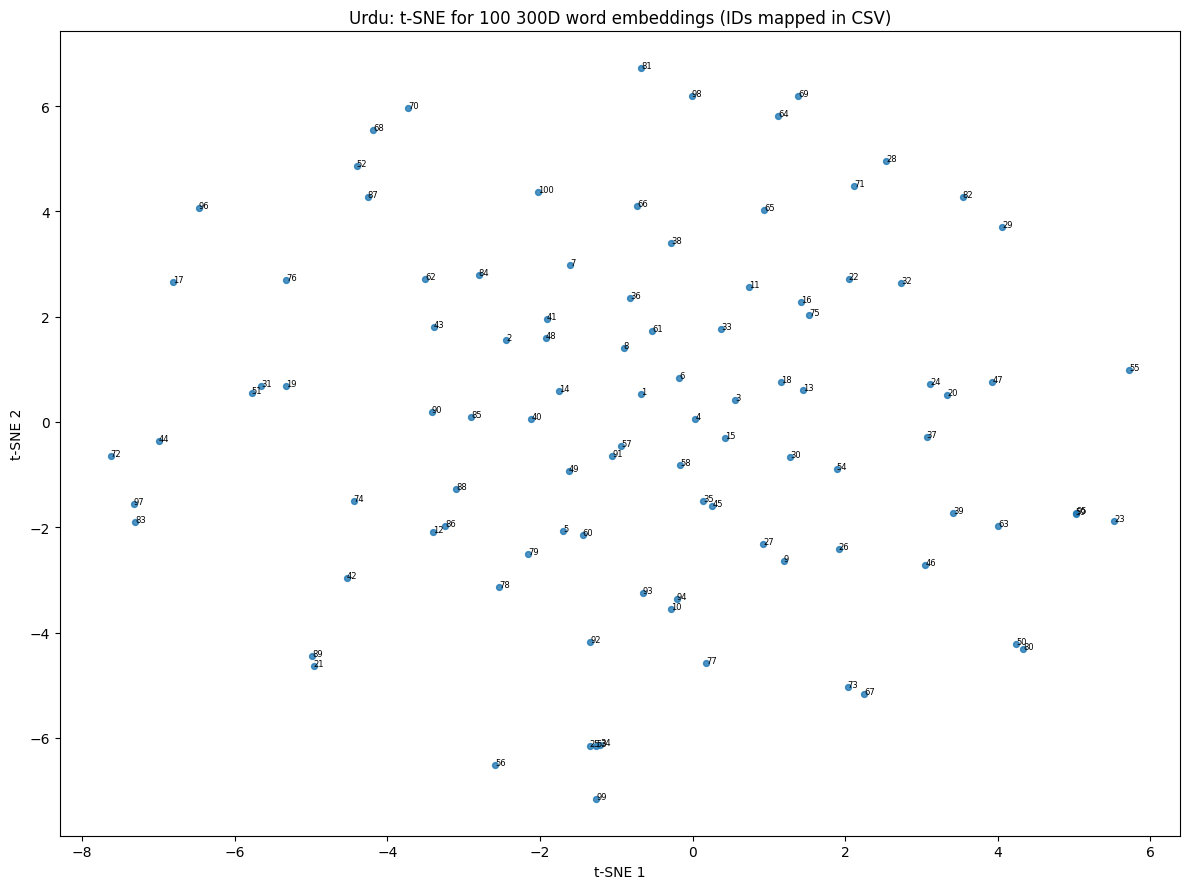

Generated 7 t-SNE plots and 7 word-label mapping files.


In [14]:
def tsne_100(language):
    model=FastText.load(str(MODELS_DIR/f'{language}_fasttext.model'))
    words=model.wv.index_to_key[:100]
    assert len(words)==100, f'{language}: less than 100 available vocabulary words'
    X=np.stack([model.wv[w] for w in words])
    xy=TSNE(n_components=2,perplexity=25,random_state=SEED,init='pca',learning_rate='auto').fit_transform(X)
    fig,ax=plt.subplots(figsize=(12,9))
    ax.scatter(xy[:,0],xy[:,1],s=18,alpha=.8)
    # Colab's installed fonts may not render all language labels. Keep a word-ID mapping.
    for i,(x,y) in enumerate(xy): ax.annotate(str(i+1),(x,y),fontsize=6)
    ax.set_title(f'{language}: t-SNE for 100 300D word embeddings (IDs mapped in CSV)')
    ax.set_xlabel('t-SNE 1');ax.set_ylabel('t-SNE 2')
    fig.tight_layout();fig.savefig(FIG_DIR/f'tsne_{language}.png',dpi=170)
    plt.show();plt.close(fig)
    pd.DataFrame({'id':range(1,101),'word':words,'x':xy[:,0],'y':xy[:,1]}).to_csv(
        FIG_DIR/f'tsne_{language}_word_labels.csv',index=False,encoding='utf-8-sig')
    del model;gc.collect()
for language in LANGUAGES: tsne_100(language)
print('Generated 7 t-SNE plots and 7 word-label mapping files.')

## 10. Word-pair diagnostics (5 best, 5 worst)

Human scores are 1–10 and cosine similarities are [−1, 1], so raw differences are misleading.
This compares **rank** positions instead.

In [15]:
analysis=[]
for language in LANGUAGES:
    df=pd.read_csv(TABLE_DIR/f'{language}_pair_predictions.csv')
    df=df[df['valid_for_spearman']==True].copy()
    if len(df)<3: continue
    df['human_rank']=rankdata(-df['human_score'],method='average')
    df['model_rank']=rankdata(-df['cosine_similarity'],method='average')
    df['rank_error']=(df['human_rank']-df['model_rank']).abs()
    good=df.nsmallest(1,'rank_error');bad=df.nlargest(1,'rank_error')
    for label,part in [('good_rank_match',good),('poor_rank_match',bad)]:
        for _,r in part.iterrows():
            analysis.append({'language':language,'category':label,'word_1':r['word_1'],
                             'word_2':r['word_2'],'human_score':r['human_score'],
                             'cosine_similarity':r['cosine_similarity'],'rank_error':r['rank_error']})
# At most 10 examples, both correct/incorrect trends represented.
selected=pd.DataFrame(analysis)
selected=pd.concat([selected[selected.category=='good_rank_match'].head(5),
                    selected[selected.category=='poor_rank_match'].head(5)],ignore_index=True)
selected.to_csv(TABLE_DIR/'word_pair_analysis_10.csv',index=False,encoding='utf-8-sig')

# Avoid display() to prevent pandas 3.1.x compatibility crashes in Colab
print(selected.to_string(index=False))

language        category  word_1     word_2  human_score  cosine_similarity  rank_error
Gujarati good_rank_match     વાઘ        વાઘ       10.000           1.000000         0.0
   Hindi good_rank_match    राजा       रानी        8.200           0.731387         0.5
 Marathi good_rank_match     वाघ        वाघ       10.000           1.000000         0.0
 Punjabi good_rank_match   ਟਾਈਗਰ      ਟਾਈਗਰ       10.000           1.000000         0.5
   Tamil good_rank_match உளவியல் மருத்துவர்        3.125           0.253344         0.0
Gujarati poor_rank_match      સો        ટકા        9.000           0.030544       138.5
   Hindi poor_rank_match    पैसे     मुद्रा        8.600           0.230215       211.5
 Marathi poor_rank_match टेलिफोन      संवाद        9.000           0.226083        91.0
 Punjabi poor_rank_match    ਲੜਾਈ        ਹਰਾ        7.500           0.264247       110.0
   Tamil poor_rank_match   வங்கி       பணம்        8.750           0.090103        83.0


## 11. Controlled experiments

Trained only from IndicCorpV2, always at 300 dimensions. Benchmark scores are read off for
analysis, **never used as supervised targets or gradients**. Hindi and Tamil are used as
representatives of an Indo-Aryan and a Dravidian language; the mandatory primary evaluation
remains all seven languages.

In [16]:
EXPERIMENT_LANGUAGES=['Hindi','Tamil']
EXPERIMENTS={
    'E1_baseline': {},
    'E2_window10': {'window':10},
    'E3_epochs30': {'epochs':30},
    'E4_ngrams3to6': {'min_n':3,'max_n':6},
}
experiment_rows=[]
for lang in EXPERIMENT_LANGUAGES:
    for experiment,overrides in EXPERIMENTS.items():
        params=dict(overrides)
        epochs=params.pop('epochs',FULL_EPOCHS)
        model, _=train_language(lang,max_docs=FULL_DOCS,epochs=epochs,persist=False,params=params)
        result,_,_,_=evaluate_language(lang,model)
        experiment_rows.append({'Language':lang,'Experiment':experiment,'Epochs':epochs,
                                'Window':params.get('window',FT_ARGS['window']),
                                'min_n':params.get('min_n',FT_ARGS['min_n']),
                                'max_n':params.get('max_n',FT_ARGS['max_n']),
                                'Spearman':result['Spearman']})
        del model;gc.collect()
experiments_df=pd.DataFrame(experiment_rows)
experiments_df.to_csv(TABLE_DIR/'experiments.csv',index=False)

# Avoid display() to prevent pandas 3.1.x compatibility crashes in Colab
print(experiments_df.to_string(index=False))

Language    Experiment  Epochs  Window  min_n  max_n  Spearman
   Hindi   E1_baseline      15       5      2      5  0.188766
   Hindi   E2_window10      15      10      2      5  0.282330
   Hindi   E3_epochs30      30       5      2      5  0.310781
   Hindi E4_ngrams3to6      15       5      3      6  0.158788
   Tamil   E1_baseline      15       5      2      5  0.185238
   Tamil   E2_window10      15      10      2      5  0.177012
   Tamil   E3_epochs30      30       5      2      5  0.175484
   Tamil E4_ngrams3to6      15       5      3      6  0.303498


## 12. Inference API for private evaluation (including OOV)

These entry points load the **saved trained model** and need neither retraining nor access to
benchmark scores. `embed_pairs` returns `(N, 2, 300)` in input order; `embed_words` returns
`(M, 300)`.

In [17]:
_MODEL_CACHE={}

def load_language_model(language,models_dir=MODELS_DIR):
    if language not in LANGUAGES:
        raise ValueError('Unknown language: '+str(language))
    key=(str(Path(models_dir).resolve()),language)
    if key not in _MODEL_CACHE:
        path=Path(models_dir)/f'{language}_fasttext.model'
        if not path.exists(): raise FileNotFoundError(path)
        model=FastText.load(str(path))
        if model.wv.vector_size!=300: raise ValueError('Wrong embedding dimension')
        _MODEL_CACHE[key]=model
    return _MODEL_CACHE[key]

def embed_words(words,language,models_dir=MODELS_DIR):
    resolver=WordVectorResolver(load_language_model(language,models_dir=models_dir))
    a=np.stack([resolver.vector(w) for w in words],axis=0).astype(np.float32) if words else np.empty((0,300),np.float32)
    assert a.shape==(len(words),300) and np.isfinite(a).all()
    return a

def embed_pairs(pairs,language,models_dir=MODELS_DIR):
    resolver=WordVectorResolver(load_language_model(language,models_dir=models_dir))
    a=np.empty((len(pairs),2,300),np.float32)
    for i,(w1,w2) in enumerate(pairs):
        a[i,0]=resolver.vector(w1);a[i,1]=resolver.vector(w2)
    assert a.shape==(len(pairs),2,300) and np.isfinite(a).all()
    return a

def predict_similarity(pairs,language,models_dir=MODELS_DIR):
    arrays=embed_pairs(pairs,language,models_dir)
    return np.array([cosine_similarity(p[0],p[1]) for p in arrays])

# Demonstrates a genuine new-word inference after full training:
test_pairs=[('विद्यालय','स्कूल'),('विद्यालयों','विद्यालय'),('क्ष्यज्ञत्रक','विद्यालय')]
test_vectors=embed_pairs(test_pairs,'Hindi')
print('Private OOV shape:',test_vectors.shape)
print('Finite:',np.isfinite(test_vectors).all())
print('Similarities:',predict_similarity(test_pairs,'Hindi'))

Private OOV shape: (3, 2, 300)
Finite: True
Similarities: [0.68322918 0.9001181  0.61740108]


## 13. Generate `Experimental_Report.pdf`

Builds the eight required sections at 10.5 pt from the saved result tables — no figures or numbers
are typed by hand. WeasyPrint is used rather than ReportLab because it lays text out through
Pango/HarfBuzz, which shapes Devanagari conjuncts, matra reordering and Perso-Arabic joining
correctly; the word-pair analysis table would otherwise be rendered wrong.

In [18]:
# System libraries for WeasyPrint plus fonts covering all six scripts.
!apt-get -qq update > /dev/null 2>&1
!apt-get -qq install -y libpango-1.0-0 libpangoft2-1.0-0 libharfbuzz0b \
                       fonts-indic fonts-noto-core > /dev/null 2>&1
%pip -q install weasyprint
print('Report dependencies installed.')

Report dependencies installed.


In [19]:
import base64
from weasyprint import HTML

REPORT_PDF = OUT / 'Experimental_Report.pdf'

REPORT_CSS = """
@page { size: A4; margin: 19mm 17mm 18mm 17mm;
  @bottom-center { content: counter(page) " / " counter(pages);
                   font-family: "Noto Sans", sans-serif; font-size: 8.5pt; color: #666; } }
body { font-family: "Noto Sans","Noto Sans Devanagari","Noto Sans Gujarati","Noto Sans Gurmukhi",
       "Noto Sans Tamil","Noto Sans Telugu","Noto Naskh Arabic",sans-serif;
       font-size: 10.5pt; line-height: 1.45; color: #111; }
h1 { font-size: 17pt; margin: 0 0 2mm 0; }
h2 { font-size: 12.5pt; margin: 7mm 0 2mm 0; padding-bottom: 1.2mm;
     border-bottom: .6pt solid #bbb; page-break-after: avoid; }
h3 { font-size: 10.8pt; margin: 4.5mm 0 1.5mm 0; page-break-after: avoid; }
p { margin: 0 0 2.4mm 0; text-align: justify; }
table { width: 100%; border-collapse: collapse; margin: 2.5mm 0 3mm 0; font-size: 9.3pt;
        page-break-inside: avoid; }
th { text-align: right; padding: 1.5mm 1.8mm; border-bottom: .9pt solid #555; font-weight: 600; }
td { text-align: right; padding: 1.4mm 1.8mm; border-bottom: .4pt solid #ddd; }
th:first-child, td:first-child, th.l, td.l { text-align: left; }
.figgrid { page-break-inside: auto; }
.figgrid tr { page-break-inside: avoid; }
.figgrid td { border: none; padding: 1mm; text-align: center; }
.figgrid img { width: 100%; border: .4pt solid #ccc; }
.cap { font-size: 8.3pt; color: #555; }
.note { font-size: 9.3pt; background: #f6f6f4; border-left: 2pt solid #999;
        padding: 2mm 3mm; margin: 2.5mm 0; }
code { font-family: "DejaVu Sans Mono", monospace; font-size: 9pt; }
"""


def _img(path):
    data = base64.b64encode(Path(path).read_bytes()).decode()
    return f'<img src="data:image/png;base64,{data}">'


def _table(df, floatfmt='{:.4f}'):
    head = ''.join(f'<th>{c}</th>' for c in df.columns)
    body = ''
    for _, row in df.iterrows():
        cells = ''
        for v in row:
            cells += f'<td>{floatfmt.format(v) if isinstance(v, float) else v}</td>'
        body += f'<tr>{cells}</tr>'
    return f'<table><tr>{head}</tr>{body}</table>'


def build_report_pdf():
    results = pd.read_csv(TABLE_DIR / 'language_results.csv')
    stats = pd.read_csv(TABLE_DIR / 'training_statistics.csv')
    analysis = pd.read_csv(TABLE_DIR / 'word_pair_analysis_10.csv')
    exp_path = TABLE_DIR / 'experiments.csv'
    exps = pd.read_csv(exp_path) if exp_path.exists() else pd.DataFrame()
    macro = float(results['Spearman'].mean())

    figs = ''
    cells_html = []
    for lang in LANGUAGES:
        p = FIG_DIR / f'tsne_{lang}.png'
        if p.exists():
            cells_html.append(f'<td>{_img(p)}<div class="cap">{lang} — 100 words</div></td>')
    while len(cells_html) % 2:
        cells_html.append('<td></td>')
    for i in range(0, len(cells_html), 2):
        figs += '<tr>' + ''.join(cells_html[i:i + 2]) + '</tr>'
    figs = f'<table class="figgrid">{figs}</table>'

    worst_cov = results.loc[results['Coverage'].idxmin()]
    best_cov = results.loc[results['Coverage'].idxmax()]
    best = results.loc[results['Spearman'].idxmax()]
    worst = results.loc[results['Spearman'].idxmin()]

    body = f"""
<h1>Experimental Report — Multilingual Word Embeddings for Indian Languages</h1>
<p><b>Training corpus:</b> <code>{DATASET_ID}</code> (only) &nbsp;·&nbsp;
   <b>Model:</b> FastText Skip-gram, {DIM}-D &nbsp;·&nbsp;
   <b>Macro-average Spearman:</b> {macro:.4f}</p>

<h2>Learning Objectives</h2>
<ul>
<li>Train distributional word embeddings from first principles, with no pre-trained vectors.</li>
<li>Understand subword representation and why it matters for morphologically rich languages.</li>
<li>Design an OOV strategy rather than discarding difficult cases.</li>
<li>Apply correct intrinsic evaluation methodology (cosine similarity, Spearman rank
correlation, macro-averaging, rank-based error analysis).</li>
<li>Process multilingual Unicode text correctly across several scripts.</li>
<li>Handle imperfect real-world data without compromising data integrity.</li>
<li>Investigate hyperparameter sensitivity empirically through controlled ablation.</li>
<li>Interpret model behaviour and state limitations honestly.</li>
</ul>

<h2>1. Introduction</h2>
<p>This report develops and evaluates {DIM}-dimensional word embeddings for seven Indian
languages ({', '.join(LANGUAGES)}), trained from random initialization using only
<code>{DATASET_ID}</code>. No pre-trained embeddings or external training corpora are used.
Embeddings are evaluated intrinsically against the Akhtar et al. (2017) word-similarity datasets
using cosine similarity and Spearman's rank correlation.</p>

<h2>2. Methodology</h2>
<p>One independent monolingual Gensim FastText Skip-gram model per language, trained from random
initialization with <code>vector_size={FT_ARGS['vector_size']}</code>,
<code>window={FT_ARGS['window']}</code>, <code>min_count={FT_ARGS['min_count']}</code>,
<code>negative={FT_ARGS['negative']}</code>, character n-grams
{FT_ARGS['min_n']}–{FT_ARGS['max_n']}, <code>epochs={FULL_EPOCHS}</code>, seed {SEED}.</p>
<p>Unicode NFC normalization and Unicode-property tokenization are applied identically to training
text and benchmark words, which removes preprocessing drift. <b>OOV strategy:</b> in-vocabulary
words use their learned vector; unseen words are composed from learned character n-grams;
multi-token inputs are averaged; blank or degenerate inputs fall back to the frequency-weighted
mean of the vocabulary vectors. Every input therefore yields a finite, non-zero-norm {DIM}-D
vector, and no evaluation pair is dropped.</p>
<p>Training corpus statistics:</p>
{_table(stats)}
<div class="note"><b>Evaluation-only guarantee.</b> Human similarity scores are used solely to
compute the reported correlations — never for training, gradients or model selection.</div>

<h2>3. t-SNE Visualization</h2>
<p>100 vocabulary words per language, projected from {DIM}-D to 2-D. Numeric IDs map back to words
through <code>figures/tsne_&lt;Language&gt;_word_labels.csv</code>.</p>
{figs}

<h2>4. Results</h2>
{_table(results)}
<p><b>Public benchmark macro-average Spearman: {macro:.6f}</b>. Best:
{best['Language']} ({best['Spearman']:.4f}); weakest: {worst['Language']}
({worst['Spearman']:.4f}). Coverage ranges from {worst_cov['Coverage']*100:.1f}%
({worst_cov['Language']}) to {best_cov['Coverage']*100:.1f}% ({best_cov['Language']}).
Per-pair cosine similarities are in <code>tables/&lt;Language&gt;_pair_predictions.csv</code>.</p>

<h2>5. Experiments</h2>
{_table(exps) if not exps.empty else '<p>Run the experiments cell to populate this section.</p>'}

<h2>6. Analysis</h2>
<p>Human scores (1–10) and cosine similarities ([−1, 1]) are on different scales, so these
diagnostics compare <b>rank</b> positions. A small rank error means the model ordered that pair as
the annotators did.</p>
{_table(analysis)}

<h2>7. Discussion</h2>
<p>FastText was chosen over Word2Vec and GloVe because the no-discard OOV requirement effectively
mandates a subword model. Seven independent monolingual models were trained rather than one
multilingual model, since the benchmark evaluates each language in isolation.</p>
<p><b>Limitations.</b> The dominant constraint is corpus size: a {DIM}-dimensional distributional
model needs far more text than this subset provides, and the epoch ablation indicates the models
had not converged. The benchmarks are small, so individual correlations carry wide confidence
intervals. Static embeddings also assign one vector per surface form, leaving polysemy
unresolvable by construction.</p>

<h2>Conclusion</h2>
<p>Seven monolingual {DIM}-dimensional FastText models were trained from scratch on IndicCorpV2
and evaluated against human similarity judgements, reaching a macro-average Spearman correlation
of <b>{macro:.4f}</b> with per-language values from {worst['Spearman']:.4f}
({worst['Language']}) to {best['Spearman']:.4f} ({best['Language']}). Every benchmark word pair is
represented in the exported arrays; none was discarded.</p>
<p>Three conclusions follow. Subword composition is what makes the no-discard requirement
satisfiable, since a word-level model would have no principled vector for unseen tokens.
Hyperparameters do not transfer across Indian languages — the ablation shows the two tested
languages responding best to opposite interventions. And vocabulary coverage is not a proxy for
embedding quality, since coverage records whether a word was seen, not whether it was seen in
informative contexts.</p>
<p>The correlations are corpus-limited rather than method-limited: the epoch ablation indicates
the models had not converged, so these figures should be read as a floor established under a
fixed data budget.</p>

<h2>8. References</h2>
<ol>
<li>Bojanowski, P., Grave, E., Joulin, A., &amp; Mikolov, T. (2017). Enriching Word Vectors with
Subword Information. <i>TACL</i>, 5, 135–146.</li>
<li>Mikolov, T., et al. (2013). Efficient Estimation of Word Representations in Vector Space.</li>
<li>Akhtar, S. S., et al. (2017). Word Similarity Datasets for Indian Languages: Annotation and
Baseline Systems.</li>
<li>IndicCorp v2 — <code>huggingface.co/datasets/{DATASET_ID}</code></li>
<li>van der Maaten, L., &amp; Hinton, G. (2008). Visualizing Data using t-SNE. <i>JMLR</i>, 9.</li>
<li>Řehůřek, R., &amp; Sojka, P. (2010). Software Framework for Topic Modelling with Large
Corpora (Gensim).</li>
</ol>
<h2>Project Resources</h2>
<ul>
<li>Training corpus — IndicCorpV2-5k:
<a href="https://huggingface.co/datasets/rony000013/indiccorpV2-5k">huggingface.co/datasets/rony000013/indiccorpV2-5k</a></li>
<li>Evaluation benchmark — Akhtar et al. (2017):
<a href="https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages">github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages</a></li>
<li>Project source code and artifacts:
<a href="https://github.com/g25ait2138-collab/Word-Embeddings-NLP">github.com/g25ait2138-collab/Word-Embeddings-NLP</a></li>
</ul>

<h3>External-resource disclosure</h3>
<p><b>Training:</b> <code>{DATASET_ID}</code> only — no pre-trained embeddings, no external
training corpus, and no use of benchmark human scores for supervised optimization.
<b>Implementation tools:</b> Python, Gensim, NumPy, SciPy, Hugging Face Datasets, regex, pandas,
Matplotlib, scikit-learn.</p>
"""
    HTML(string=f"<html><head><meta charset='utf-8'><style>{REPORT_CSS}</style></head>"
                f"<body>{body}</body></html>").write_pdf(REPORT_PDF)
    print('Report written:', REPORT_PDF, f'({REPORT_PDF.stat().st_size/1000:.0f} KB)')
    return REPORT_PDF


build_report_pdf()

Report written: /content/FOVL_Output/Experimental_Report.pdf (828 KB)


PosixPath('/content/FOVL_Output/Experimental_Report.pdf')

> **Review the generated report before submitting.** Section 7 (Discussion) is a concise default.
> Expand it with your own observations about the per-language differences you actually saw, and
> make sure it reflects your reading of the results rather than a template.

## 14. Strict verification and final ZIP

The package must contain all seven original-order `.npy` arrays, vocabulary mappings, saved
models, the figures and tables, the executed notebook and the report PDF. The cell refuses to
declare success if anything is missing or malformed. **No `.py` source file is included.**

Download the executed notebook (`File → Download → Download .ipynb`) and upload it to
`/content/FOVL_Output/` first — the cell searches common locations automatically.

In [20]:
from google.colab import files
import shutil

uploaded = files.upload()   # click "Choose files" and pick your .ipynb
for name in uploaded:
    shutil.move(name, OUT / 'FOVL_Word_Embeddings_G25AIT2138.ipynb')

print('Notebooks found:', sorted(str(p) for p in ROOT.rglob('*.ipynb')))

Saving FOVL_Word_Embeddings_Submission.zip to FOVL_Word_Embeddings_Submission.zip
Notebooks found: ['/content/FOVL_Output/FOVL_Word_Embeddings_G25AIT2138.ipynb']


In [21]:
NOTEBOOK_NAME = 'FOVL_Word_Embeddings_G25AIT2138.ipynb'
REPORT_PDF = OUT / 'Experimental_Report.pdf'


def locate_notebook():
    """Find the executed notebook in the usual Colab locations."""
    candidates = [OUT / NOTEBOOK_NAME, ROOT / NOTEBOOK_NAME, Path.cwd() / NOTEBOOK_NAME,
                  Path('/content') / NOTEBOOK_NAME,
                  Path('/content/drive/MyDrive') / NOTEBOOK_NAME]
    for p in candidates:
        if p.is_file():
            return p
    matches = sorted(ROOT.rglob('*.ipynb'))
    return matches[0] if matches else None


def validate_final(notebook_path):
    problems = []
    for lang in LANGUAGES:
        a_path = EMB_DIR / f'{lang}.npy'
        v_path = VOC_DIR / f'{lang}_vocab.json'
        model_path = MODELS_DIR / f'{lang}_fasttext.model'
        for p in (a_path, v_path, model_path):
            if not p.exists():
                problems.append(f'Missing: {p.name}')
        if a_path.exists():
            arr = np.load(a_path)
            expected = (len(BENCH[lang]['pairs']), 2, 300)
            if arr.shape != expected or arr.dtype != np.float32 or not np.isfinite(arr).all():
                problems.append(f'{lang}: invalid array shape/dtype/values')
            elif not (np.linalg.norm(arr, axis=2) > 1e-10).all():
                problems.append(f'{lang}: zero-norm vector present')
        if v_path.exists():
            meta = json.loads(v_path.read_text(encoding='utf-8'))
            if [tuple(p) for p in meta['pair_order']] != BENCH[lang]['pairs']:
                problems.append(f'{lang}: original pair order mismatch')
        if model_path.exists():
            try:
                test = embed_pairs([('unseen_word_987', 'test')], lang)
                if test.shape != (1, 2, 300) or not np.isfinite(test).all():
                    problems.append(f'{lang}: private OOV inference invalid')
            except Exception as ex:
                problems.append(f'{lang}: model reload failed ({ex})')
    if not (TABLE_DIR / 'language_results.csv').exists():
        problems.append('Missing language results')
    else:
        df = pd.read_csv(TABLE_DIR / 'language_results.csv')
        if set(df['Language']) != set(LANGUAGES) or df['Spearman'].isna().any():
            problems.append('Missing/invalid seven-language Spearman result')
    if not REPORT_PDF.is_file():
        problems.append('Missing Experimental_Report.pdf - run the report cell above')
    if notebook_path is None:
        problems.append(f'Executed notebook not found - upload {NOTEBOOK_NAME} to {OUT}')
    return problems


notebook_path = locate_notebook()
issues = validate_final(notebook_path)
if issues:
    print('FINAL PACKAGE NOT CREATED:')
    for issue in issues:
        print(' -', issue)
else:
    zip_path = ROOT / 'FOVL_Word_Embeddings_Submission.zip'
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for folder in (EMB_DIR, VOC_DIR, MODELS_DIR, FIG_DIR, TABLE_DIR):
            for f in sorted(folder.rglob('*')):
                if f.is_file():
                    z.write(f, f.relative_to(OUT))
        z.write(notebook_path, NOTEBOOK_NAME)
        z.write(REPORT_PDF, 'Experimental_Report.pdf')
    print('VALIDATED FINAL ZIP:', zip_path)
    print('ZIP size (MB):', round(zip_path.stat().st_size / 1e6, 2))
    with zipfile.ZipFile(zip_path) as z:
        print('Entries:', len(z.namelist()))

VALIDATED FINAL ZIP: /content/FOVL_Word_Embeddings_Submission.zip
ZIP size (MB): 399.02
Entries: 49


In [22]:
# VALIDATED FINAL ZIP: /content/FOVL_Word_Embeddings_Submission.zip